# 02.2 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/02-linear-regression-by-hand/solutions.ipynb)

## Exercise 1

$\bar{x} = 2.5$, $\bar{y} = 6$.

| $x$ | $y$ | $x-\bar x$ | $y-\bar y$ | product | $(x-\bar x)^2$ |
|---|---|---|---|---|---|
| 1 | 3 | −1.5 | −3 | 4.5 | 2.25 |
| 2 | 5 | −0.5 | −1 | 0.5 | 0.25 |
| 3 | 7 | 0.5 | 1 | 0.5 | 0.25 |
| 4 | 9 | 1.5 | 3 | 4.5 | 2.25 |
| | | | sum | **10** | **5** |

$m = 10/5 = 2$, $c = 6 - 2 \times 2.5 = 1$. Line: $\hat y = 2x + 1$. Every point lies exactly on it, so the sum of squared residuals is **0**.

In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression
x = np.array([1, 2, 3, 4.]); y = np.array([3, 5, 7, 9.])
mdl = LinearRegression().fit(x.reshape(-1, 1), y)
resid = y - mdl.predict(x.reshape(-1, 1))
print("m =", mdl.coef_[0], " c =", mdl.intercept_, " SSE =", (resid**2).sum())

m = 2.0  c = 1.0  SSE = 0.0


## Exercise 2

$\bar x = 6$ (unchanged), $\bar y = (50+80+190+130+150)/5 = 120$.

Deviations of $y$: −70, −40, 70, 10, 30. Products with $x-\bar x$ (−4, −2, 0, 2, 4): 280, 80, 0, 20, 120 → sum **500**. Denominator is still **40**.

$m = 500/40 = 12.5$ (unchanged, because C003 sits at $x = \bar x$ and contributes 0 to the numerator), $c = 120 - 12.5 \times 6 = 45$.

The whole line moved **up by 20** to chase one point. C003 now has the largest residual: $190 - (12.5 \times 6 + 45) = 190 - 120 = 70$.

old: m=12.5, c=25.0
new: m=12.5, c=45.0
new residuals: [-20. -15.  70. -15. -20.]


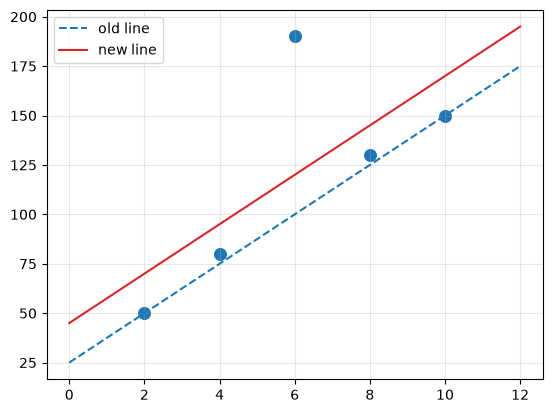

In [2]:
import matplotlib.pyplot as plt
x = np.array([2, 4, 6, 8, 10.])
y_old = np.array([50, 80, 90, 130, 150.])
y_new = np.array([50, 80, 190, 130, 150.])

old = LinearRegression().fit(x.reshape(-1, 1), y_old)
new = LinearRegression().fit(x.reshape(-1, 1), y_new)
print(f"old: m={old.coef_[0]:.1f}, c={old.intercept_:.1f}")
print(f"new: m={new.coef_[0]:.1f}, c={new.intercept_:.1f}")
print("new residuals:", (y_new - new.predict(x.reshape(-1, 1))).round(1))

xs = np.linspace(0, 12, 50)
plt.scatter(x, y_new, s=70)
plt.plot(xs, old.predict(xs.reshape(-1, 1)), "--", label="old line")
plt.plot(xs, new.predict(xs.reshape(-1, 1)), color="tab:red", label="new line")
plt.legend(); plt.grid(alpha=.3); plt.show()

If C003 had been at $x = 2$ instead, the slope would also have changed. Outliers far from $\bar x$ have the most leverage.

## Exercise 3

In [3]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd
cust = pd.read_csv(data_path("shopwave_customers_small.csv"))
for col in ["visits_last_month", "items_last_month"]:
    mdl = LinearRegression().fit(cust[[col]], cust["spend_next_month"])
    print(f"{col:<20} slope = £{mdl.coef_[0]:.2f} per unit, intercept = {mdl.intercept_:.1f}")

visits_last_month    slope = £17.17 per unit, intercept = 19.6
items_last_month     slope = £29.62 per unit, intercept = 4.0


The slope for items is larger: each extra *item bought* is worth more pounds than each extra *visit*, which is sensible, since buying is closer to spending than browsing. Both are only one-feature views; Lesson 02.5 uses them together.

## Exercise 4

In [4]:
rng = np.random.default_rng(0)
x = np.array([2, 4, 6, 8, 10.]); y = np.array([50, 80, 90, 130, 150.])
best = np.inf
for _ in range(10_000):
    m_try = rng.uniform(0, 25); c_try = rng.uniform(-50, 100)
    sse = ((y - (m_try * x + c_try)) ** 2).sum()
    best = min(best, sse)
print(f"best random SSE: {best:.2f}   (least squares: 150.00)")

best random SSE: 151.37   (least squares: 150.00)


Random search gets close to 150 but never below it. The formula is not an approximation; it is the exact minimum.